In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from datetime import timedelta
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
def deseasonalize(data_arr):
    #compute monthly mean
    seasonal_mean = data_arr.groupby('time.month').mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.month') - seasonal_mean
    return deseasonalized_data_arr

In [3]:
def find_box_corners(plon,plat,lon_edge,lat_edge):
    lat_min, lat_max = (plat-lat_edge/2)-20,plat+(lat_edge/2)
    lon_min, lon_max = (plon-lon_edge/2),plon+(lon_edge/2)
    if lon_max % 2.5 == 0:
        lon_max -= 0.0001
    if lat_max % 2.5 == 0:
        lat_max -= 0.0001
    return lat_min,lat_max,lon_min,lon_max

In [20]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

In [21]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW_mod.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [22]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries/
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC_tyrlis_EW_mod.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dics =(dic_for_filtering_DAV,dic_for_filtering_GHA)

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries


In [24]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
np_array_GHA = GHA_filt.values
np_array_DAV = DAV_filt.values
np_arrays = (np_array_DAV,np_array_GHA)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
months = ['06','07','08']

In [25]:
labels = [[],[]]
timings = [[],[]]
min_pers = (3,3)
for t,time in tqdm(enumerate(times)):
    if t > len(times.values)-5:
        break
    for i,arr in enumerate(np_arrays):
        labels_of_the_day = np.unique(arr[t,mask_bool])
        for label in labels_of_the_day:
            check_cond = []
            for k in range(min_pers[i]):
                #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                check_cond.append(np.any(arr[t+k,mask_bool]==label))
            if label not in labels[i] and np.all(check_cond) and label!=0:
                labels[i].append(label)
                timings[i].append(t)

30677it [00:24, 1263.83it/s]


In [26]:
labels_retrograding = [[],[]]
labels_upstream = [[],[]]
#populating the lists
for i,arr in enumerate(np_arrays):
    for j,label in tqdm(enumerate(labels[i])):
        left_or_right = (dics[i][label]['track'][1][-1] - dics[i][label]['track'][1][0]) > 0
        if dics[i][label]['track'][1][0] > plon:
            labels_retrograding[i].append(label)
        if dics[i][label]['track'][1][0] <= plon:
            labels_upstream[i].append(label)

1239it [00:00, 311294.04it/s]
921it [00:00, 317442.19it/s]


### YMONMEAN analysis

In [27]:
ymonmean_DAV = np.zeros((3,12))
ymonmean_GHA = np.zeros((3,12))
mask_size = np.sum(mask_xr,axis=(0,1))
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    month = int(str(time.values)[5:7])-1
    for l in np.unique(DAV_gr):
        if l in labels_retrograding[0] or l in labels_upstream[0]:
            ymonmean_DAV[0][month] += 1
        if l in labels_retrograding[0]:
            ymonmean_DAV[1][month] += 1
        if l in labels_upstream[0]:
            ymonmean_DAV[2][month] += 1
    for l in np.unique(GHA_gr):
        if l in labels_retrograding[1] or l in labels_upstream[1]:
            ymonmean_GHA[0][month] += 1
        if l in labels_retrograding[1]:
            ymonmean_GHA[1][month] += 1
        if l in labels_upstream[1]:
            ymonmean_GHA[2][month] += 1

30681it [00:21, 1441.65it/s]


Text(0.5, 0.98, '')

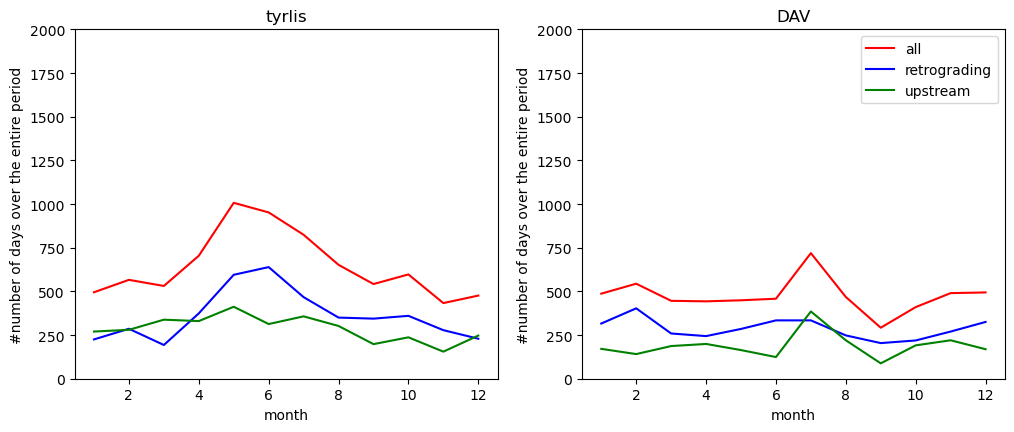

In [28]:
months = np.arange(1,13,1)

titles = ['tyrlis','DAV']
freqs = [ymonmean_DAV,ymonmean_GHA]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
for i in range(2):

    axes[i].plot(months,freqs[i][0],color='r',label='all')
    axes[i].plot(months,freqs[i][1],color='b',label='retrograding')
    axes[i].plot(months,freqs[i][2],color='g',label='upstream')
    axes[i].set_title(titles[i])
    axes[i].set_ylim((0,2000))
    axes[i].set_xlabel('month')
    axes[i].set_ylabel('#number of days over the entire period')
    axes[i].set_aspect(0.005)


plt.legend()
    
fig.suptitle('', fontsize=20)
